# Лабораторная работа № 1
## Решение варианта № 13

**Дисциплина:** «Методы анализа больших данных»  
**Профиль:** «Информатика и английский язык»  
**Среда:** Google Colab, Python 3.10+

### Постановка задачи

Для учащихся с `parental level of education == "some high school"` исследовать связь между баллами по чтению (`reading score`) и по письму (`writing score`).

Перед анализом проверить качество данных, обработать пропуски (медиана) и потенциальные выбросы методом IQR. Затем описать подгруппу (основная мера центра — **медиана**) и проверить гипотезу о положительной связи двух баллов односторонним тестом значимости коэффициента корреляции Пирсона при $\alpha=0.05$.

**Дополнительно:** повторить основные расчёты для очищенных данных в **BigQuery** и сопоставить их с результатами `pandas`.



## Блок 1. Импорт библиотек и прямая загрузка датасета

Основной URL берётся строго из условия лабораторной работы. Если он недоступен по сетевой или HTTP-причине, код автоматически обращается к резервному публичному URL на тот же `StudentsPerformance.csv`.

Ручная загрузка файла в Colab не используется.


In [1]:
import io
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

PRIMARY_URL = "https://raw.githubusercontent.com/sriharikadali/Students-Performance-in-Exams/master/StudentsPerformance.csv"
FALLBACK_URL = "https://raw.githubusercontent.com/NadavKiani/Students-Performance-in-Exams/master/StudentsPerformance.csv"


def load_students_performance(primary_url: str, fallback_url: str):
    """
    Загружает CSV непосредственно по HTTPS.
    Сначала используется URL из задания, затем резервный URL.
    """
    errors = []

    for url in (primary_url, fallback_url):
        try:
            with urllib.request.urlopen(url, timeout=30) as response:
                raw_bytes = response.read()

            dataframe = pd.read_csv(io.BytesIO(raw_bytes))

            required_columns = {
                "gender",
                "race/ethnicity",
                "parental level of education",
                "lunch",
                "test preparation course",
                "math score",
                "reading score",
                "writing score",
            }

            missing_columns = required_columns - set(dataframe.columns)
            if missing_columns:
                raise ValueError(
                    f"Отсутствуют обязательные столбцы: {sorted(missing_columns)}"
                )

            return dataframe, url

        except Exception as exc:
            errors.append(
                f"{url} -> {type(exc).__name__}: {exc}"
            )

    raise RuntimeError(
        "Не удалось загрузить датасет.\n" + "\n".join(errors)
    )


df_raw, USED_URL = load_students_performance(PRIMARY_URL, FALLBACK_URL)

print("Dataset loaded successfully / Датасет успешно загружен")
print("Used URL / Использованный URL:")
print(USED_URL)
print("Shape / Размер:", df_raw.shape)

display(df_raw.head())


Dataset loaded successfully / Датасет успешно загружен
Used URL / Использованный URL:
https://raw.githubusercontent.com/NadavKiani/Students-Performance-in-Exams/master/StudentsPerformance.csv
Shape / Размер: (1000, 8)


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


### Короткое пояснение результата

Загружен датасет из **1000 строк и 8 столбцов**. Использован резервный URL, потому что основной адрес во время запуска оказался недоступен. Структура файла соответствует условию лабораторной работы.

## Блок 2. Первичная проверка и контроль качества

Проверяются:

- структура таблицы;
- типы данных;
- пропуски $NaN$;
- полные дубликаты;
- диапазон баллов 0–100;
- значения категориальных полей.

Доля пропусков:

$$
r_{miss}=\frac{N_{miss}}{N}.
$$


In [2]:
score_cols = ["math score", "reading score", "writing score"]

categorical_cols = [
    "gender",
    "race/ethnicity",
    "parental level of education",
    "lunch",
    "test preparation course",
]

print("Rows, columns / Строки, столбцы:", df_raw.shape)

print("\n--- INFO ---")
df_raw.info()

print("\n--- FIRST ROWS / ПЕРВЫЕ СТРОКИ ---")
display(df_raw.head())

missing_report = df_raw.isna().sum().to_frame("missing_count")
missing_report["missing_percent"] = (
    missing_report["missing_count"] / len(df_raw) * 100
)

print("\n--- MISSING VALUES / ПРОПУСКИ ---")
display(missing_report)

duplicate_count = int(df_raw.duplicated().sum())
print("Exact duplicates / Полные дубликаты:", duplicate_count)

print("\n--- NUMERIC DESCRIPTION / ЧИСЛОВАЯ СТАТИСТИКА ---")
display(df_raw[score_cols].describe().T)

range_check = pd.DataFrame({
    "below_0": (df_raw[score_cols] < 0).sum(),
    "above_100": (df_raw[score_cols] > 100).sum(),
})

print("\n--- RANGE CHECK 0..100 / ПРОВЕРКА ДИАПАЗОНА ---")
display(range_check)

for col in categorical_cols:
    print(f"\nColumn / Столбец: {col}")
    display(df_raw[col].value_counts(dropna=False).to_frame("count"))


Rows, columns / Строки, столбцы: (1000, 8)

--- INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB

--- FIRST ROWS / ПЕРВЫЕ СТРОКИ ---


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75



--- MISSING VALUES / ПРОПУСКИ ---


,missing_count,missing_percent
gender,0,0.0
race/ethnicity,0,0.0
parental level of education,0,0.0
lunch,0,0.0
test preparation course,0,0.0
math score,0,0.0
reading score,0,0.0
writing score,0,0.0


Exact duplicates / Полные дубликаты: 0

--- NUMERIC DESCRIPTION / ЧИСЛОВАЯ СТАТИСТИКА ---


...

,count
parental level of education,
some college,226
associate's degree,222
high school,196
some high school,179
bachelor's degree,118
master's degree,59



Column / Столбец: lunch


,count
lunch,
standard,645
free/reduced,355



Column / Столбец: test preparation course


,count
test preparation course,
none,642
completed,358


### Короткое пояснение результата

В исходных данных **нет пропусков и полных дубликатов**. Все три экзаменационных балла находятся в допустимом диапазоне **0–100**. Значит, дополнительного исправления пропусков для этого запуска не требуется, но код обработки оставлен как часть воспроизводимого конвейера.

### Обработка пропусков варианта № 13

Даже если исходный файл не содержит `NaN`, алгоритм обработки должен быть реализован полностью:

- числовые признаки → медиана;
- категориальные признаки → мода.

Исходный `df_raw` не изменяется.


In [3]:
df = df_raw.copy()

# Удаление полных дублей, если они есть.
n_before = len(df)
df = df.drop_duplicates().copy()
n_after = len(df)

print(
    "Removed exact duplicates / Удалено полных дублей:",
    n_before - n_after
)

# Медианная импутация числовых полей.
for col in score_cols:
    missing_before = int(df[col].isna().sum())
    median_value = df[col].median()

    df[col] = df[col].fillna(median_value)

    print(
        f"{col}: NaN before={missing_before}; "
        f"median={median_value:.2f}"
    )

# Импутация модой категориальных полей.
for col in categorical_cols:
    missing_before = int(df[col].isna().sum())

    if missing_before > 0:
        mode_series = df[col].mode(dropna=True)

        if mode_series.empty:
            raise ValueError(
                f"Невозможно определить моду для столбца {col}"
            )

        mode_value = mode_series.iloc[0]
        df[col] = df[col].fillna(mode_value)
    else:
        mode_value = "not required / не требуется"

    print(
        f"{col}: NaN before={missing_before}; "
        f"mode={mode_value}"
    )

print("\nNaN after imputation / Пропуски после импутации:")
display(df.isna().sum().to_frame("missing_count"))


Removed exact duplicates / Удалено полных дублей: 0
math score: NaN before=0; median=66.00
reading score: NaN before=0; median=70.00
writing score: NaN before=0; median=69.00
gender: NaN before=0; mode=not required / не требуется
race/ethnicity: NaN before=0; mode=not required / не требуется
parental level of education: NaN before=0; mode=not required / не требуется
lunch: NaN before=0; mode=not required / не требуется
test preparation course: NaN before=0; mode=not required / не требуется

NaN after imputation / Пропуски после импутации:


,missing_count
gender,0
race/ethnicity,0
parental level of education,0
lunch,0
test preparation course,0
math score,0
reading score,0
writing score,0


### Короткое пояснение результата

Импутация фактически не изменила таблицу: во всех столбцах было `0` пропусков. Медианы числовых признаков рассчитаны корректно, но подстановка значений не потребовалась.

## Блок 3. Поиск и обработка выбросов методом IQR

Для каждого экзаменационного показателя:

$$
IQR=Q_3-Q_1,
$$

$$
L=Q_1-1.5\cdot IQR,
$$

$$
U=Q_3+1.5\cdot IQR.
$$

Строка исключается в учебном решении, если хотя бы один из трёх баллов находится вне своего IQR-интервала.

В реальном образовательном исследовании такие наблюдения сначала должны проходить предметную проверку: низкий или высокий балл может быть редким, но корректным результатом.


In [4]:
iqr_bounds = {}
outlier_mask = pd.Series(False, index=df.index)

for col in score_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    iqr_bounds[col] = {
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower": lower,
        "upper": upper,
    }

    current_outliers = (
        (df[col] < lower) |
        (df[col] > upper)
    )

    outlier_mask = outlier_mask | current_outliers

bounds_df = pd.DataFrame(iqr_bounds).T

bounds_df["outlier_count"] = [
    int(
        (
            (df[col] < bounds_df.loc[col, "lower"]) |
            (df[col] > bounds_df.loc[col, "upper"])
        ).sum()
    )
    for col in score_cols
]

display(bounds_df.round(3))

print(
    "Rows with >=1 IQR outlier / "
    "Строк с хотя бы одним IQR-выбросом:",
    int(outlier_mask.sum())
)

df_clean = df.loc[~outlier_mask].copy()

print("Rows before / Строк до очистки:", len(df))
print("Rows after / Строк после очистки:", len(df_clean))
print("Removed / Удалено:", len(df) - len(df_clean))

# Контроль качества после очистки.
assert df_clean[score_cols].notna().all().all()
assert (
    ((df_clean[score_cols] >= 0) &
     (df_clean[score_cols] <= 100))
    .all()
    .all()
)

display(df_clean.head())


,Q1,Q3,IQR,lower,upper,outlier_count
math score,57.00,77.0,20.00,27.000,107.000,8
reading score,59.00,79.0,20.00,29.000,109.000,6
writing score,57.75,79.0,21.25,25.875,110.875,5


Rows with >=1 IQR outlier / Строк с хотя бы одним IQR-выбросом: 12
Rows before / Строк до очистки: 1000
Rows after / Строк после очистки: 988
Removed / Удалено: 12


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


### Короткое пояснение результата

Метод IQR отметил **12 строк** как содержащие хотя бы один потенциальный выброс. После учебной очистки осталось **988 строк**.

> Потенциальный выброс не обязательно является ошибкой. В реальном образовательном исследовании такие наблюдения сначала нужно проверить содержательно.

### Фильтрация варианта № 13

Оставляем учащихся с `parental level of education == "some high school"` (фильтрация по одному условию). Для них смотрим описательную статистику по `reading score` и `writing score`. Основная мера центра — медиана, рядом приводятся среднее, стандартное отклонение, квартили Q1 и Q3, минимум и максимум.


In [5]:
v13_cols = ["reading score", "writing score"]

df_v13 = df_clean.loc[
    df_clean["parental level of education"].eq("some high school")
].copy()

print(
    "Variant 13 sample / Выборка варианта №13:",
    df_v13.shape
)

stats_v13 = (
    df_v13[v13_cols]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .T
)
stats_v13["Q1"] = df_v13[v13_cols].quantile(0.25)
stats_v13["Q3"] = df_v13[v13_cols].quantile(0.75)

display(stats_v13.round(2))


Variant 13 sample / Выборка варианта №13: (175, 8)


,count,mean,median,std,min,max,Q1,Q3
reading score,175.0,67.82,67.0,14.44,31.0,100.0,58.0,79.0
writing score,175.0,65.87,67.0,14.44,32.0,100.0,54.5,77.5


### Короткое пояснение результата

После фильтра `parental level of education == "some high school"` осталось **175 учащихся**.

- `reading score`: медиана **67**, среднее **67,82**, Q1 = 58, Q3 = 79;
- `writing score`: медиана **67**, среднее **65,87**, Q1 = 54,5, Q3 = 77,5.

Медианы по чтению и письму совпадают, а среднее по письму чуть ниже. Далее посмотрим на графиках и проверим статистически, связаны ли два балла между собой.


## Блок 4. Визуализация

Строятся три обязательных графика и одна дополнительная диаграмма рассеяния, которая лучше всего показывает саму связь:

1. Boxplot.
2. Histplot.
3. Scatter plot с линией регрессии (дополнительно).
4. Correlation Heatmap.

Подписи выполняются на английском и русском языках.


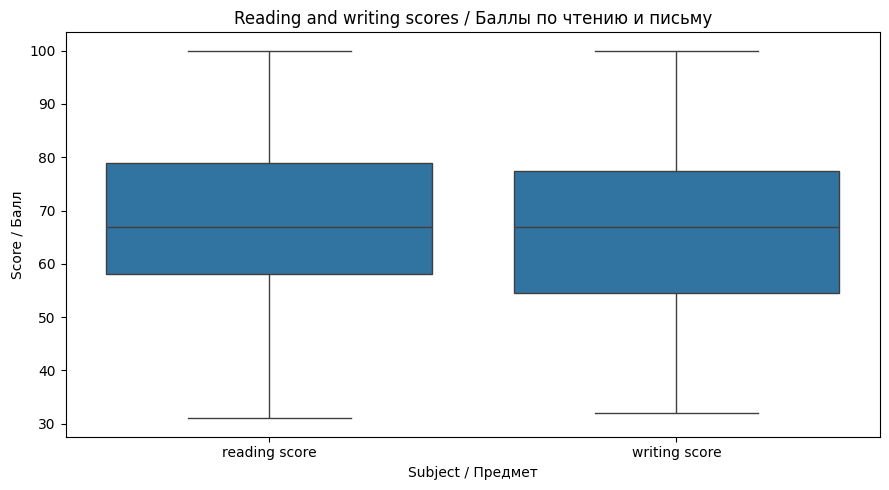

In [6]:
# 1. BOXPLOT
df_long = df_v13[v13_cols].melt(
    var_name="subject",
    value_name="score"
)

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df_long,
    x="subject",
    y="score"
)

plt.title(
    "Reading and writing scores / "
    "Баллы по чтению и письму"
)
plt.xlabel("Subject / Предмет")
plt.ylabel("Score / Балл")

plt.tight_layout()
plt.show()


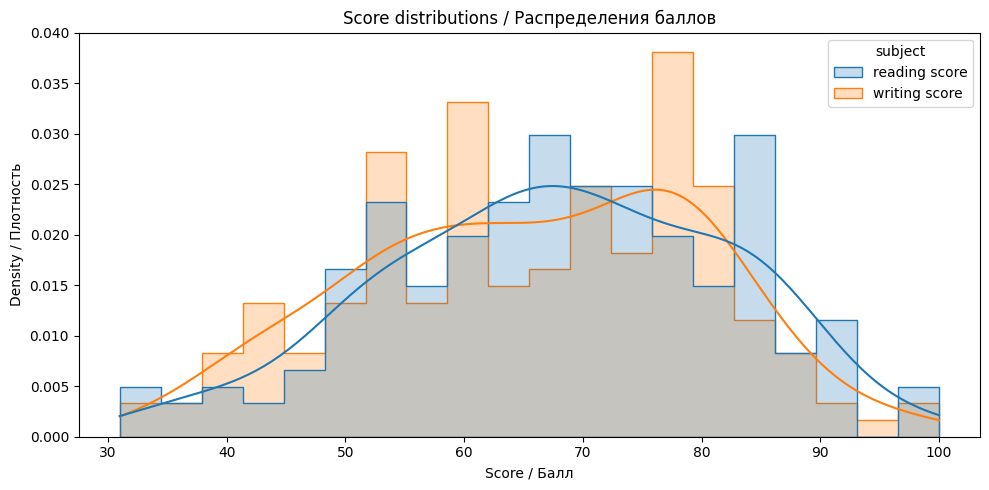

In [7]:
# 2. HISTPLOT
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_long,
    x="score",
    hue="subject",
    bins=20,
    kde=True,
    element="step",
    stat="density",
    common_norm=False
)

plt.title(
    "Score distributions / "
    "Распределения баллов"
)
plt.xlabel("Score / Балл")
plt.ylabel("Density / Плотность")

plt.tight_layout()
plt.show()


<Figure size 700x600 with 0 Axes>

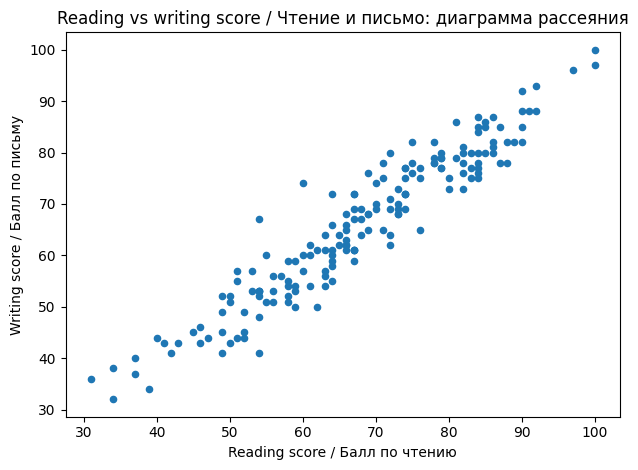

In [8]:
# 3. SCATTER PLOT (дополнительно)
plt.figure(figsize=(7, 6))
pd.DataFrame(np.array([df_v13["reading score"],df_v13["writing score"]]).T).plot.scatter(0, 1, s = 20)

plt.title(
    "Reading vs writing score / "
    "Чтение и письмо: диаграмма рассеяния"
)
plt.xlabel("Reading score / Балл по чтению")
plt.ylabel("Writing score / Балл по письму")

plt.tight_layout()
plt.show()


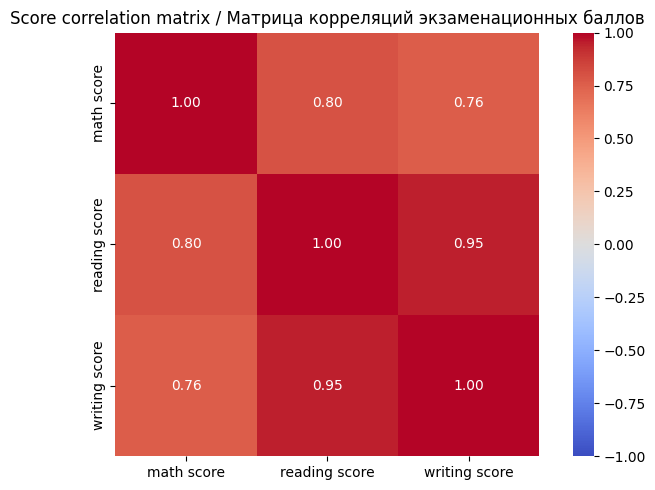

,math score,reading score,writing score
math score,1.000,0.803,0.760
reading score,0.803,1.000,0.951
writing score,0.760,0.951,1.000


In [9]:
# 4. CORRELATION HEATMAP
corr_matrix = df_v13[score_cols].corr(method="pearson")

plt.figure(figsize=(7, 5))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    square=True,
    vmin=-1,
    vmax=1,
    cmap="coolwarm"
)

plt.title(
    "Score correlation matrix / "
    "Матрица корреляций экзаменационных баллов"
)

plt.tight_layout()
plt.show()

display(corr_matrix.round(3))


### Короткое пояснение результата

Распределения `reading score` и `writing score` в подгруппе очень похожи по форме и положению. На диаграмме рассеяния точки вытянуты вдоль восходящей линии: чем выше балл по чтению, тем, как правило, выше балл по письму. В матрице корреляций связь между `reading score` и `writing score` самая сильная: **r ≈ 0,951**. Связь этих двух баллов с математикой слабее: около 0,80 и 0,76.

Корреляция показывает совместное изменение показателей, но сама по себе не доказывает причинность.


## Блок 5. Проверка гипотезы варианта № 13

Применяется односторонний тест значимости коэффициента корреляции Пирсона:

$$
H_0:\ \rho\leq 0
$$

$$
H_1:\ \rho>0
$$

$$
\alpha=0.05,
$$

где $\rho$ — коэффициент корреляции между `reading score` и `writing score` в подгруппе `some high school`.

Правило решения:

- при $p<0.05$ отклоняем $H_0$ в пользу положительной связи;
- при $p\geq0.05$ статистических оснований для вывода о положительной связи недостаточно.


In [10]:
x = df_v13["reading score"].astype(float)
y = df_v13["writing score"].astype(float)
n = len(df_v13)

print("n =", n)
print(f"reading: median = {x.median():.1f}, mean = {x.mean():.3f}")
print(f"writing: median = {y.median():.1f}, mean = {y.mean():.3f}")

# Современные scipy поддерживают alternative="greater".
# Блок except оставлен для совместимости со старыми средами.
try:
    pearson_res = stats.pearsonr(x, y, alternative="greater")
    r_pearson = float(pearson_res[0])
    p_pearson = float(pearson_res[1])
except TypeError:
    r_pearson, p_two_sided = stats.pearsonr(x, y)
    r_pearson = float(r_pearson)
    p_two_sided = float(p_two_sided)
    p_pearson = p_two_sided / 2 if r_pearson > 0 else 1 - p_two_sided / 2

alpha = 0.05

print("\nOne-sided correlation tests (H1: positive association)")
print(f"Pearson  r   = {r_pearson:.4f}, p = {p_pearson:.4g}")
print(f"alpha = {alpha}")


n = 175
reading: median = 67.0, mean = 67.823
writing: median = 67.0, mean = 65.874

One-sided correlation tests (H1: positive association)
Pearson  r   = 0.9510, p = 1.949e-90
alpha = 0.05


### Короткое пояснение результата

Для пары `reading score` и `writing score` в подгруппе `some high school` получен коэффициент Пирсона **r ≈ 0,951**, $p\approx1{,}9\cdot10^{-90}$.

Так как $p<0.05$, нулевая гипотеза отклоняется в пользу положительной связи: **в этой подгруппе** баллы по чтению и по письму положительно связаны. Значение $r$ близко к 1, то есть связь сильная. Это не означает, что один навык является причиной другого.


### Автоматическая формулировка вывода

Код ниже формирует статистический вывод и отдельно — педагогическую интерпретацию. Это разделение принципиально: статистическая связь в наблюдательном наборе не доказывает причинного влияния.


In [11]:
print("=" * 78)
print("STATISTICAL CONCLUSION / СТАТИСТИЧЕСКИЙ ВЫВОД")
print("=" * 78)

if p_pearson < alpha and r_pearson > 0:
    print(
        f"p={p_pearson:.4g} < {alpha}. "
        "H0 отклоняется в пользу H1."
    )
    print(f"Pearson r={r_pearson:.3f}.")
    print(
        "In this subgroup, reading and writing scores "
        "are positively associated."
    )
    print(
        "В данной подгруппе баллы по чтению и письму "
        "положительно связаны."
    )
else:
    print(
        f"p={p_pearson:.4g}. "
        "Недостаточно оснований подтвердить "
        "положительную связь."
    )

print("\n" + "=" * 78)
print("PEDAGOGICAL INTERPRETATION / ПЕДАГОГИЧЕСКИЙ ВЫВОД")
print("=" * 78)

print(
    "В анализируемой подгруппе можно говорить о статистической связи "
    "между баллами по чтению и по письму."
)

print(
    "Нельзя утверждать, что высокий балл по чтению является причиной "
    "высокого балла по письму: на оба результата могли влиять общая "
    "учебная подготовка, мотивация и другие неучтённые факторы."
)

print(
    "Для школьного урока корректная формулировка: "
    "'В этой подгруппе баллы связаны' — "
    "а не 'хорошее чтение гарантированно улучшает письмо'."
)


STATISTICAL CONCLUSION / СТАТИСТИЧЕСКИЙ ВЫВОД
p=1.949e-90 < 0.05. H0 отклоняется в пользу H1.
Pearson r=0.951.
In this subgroup, reading and writing scores are positively associated.
В данной подгруппе баллы по чтению и письму положительно связаны.

PEDAGOGICAL INTERPRETATION / ПЕДАГОГИЧЕСКИЙ ВЫВОД
В анализируемой подгруппе можно говорить о статистической связи между баллами по чтению и по письму.
Нельзя утверждать, что высокий балл по чтению является причиной высокого балла по письму: на оба результата могли влиять общая учебная подготовка, мотивация и другие неучтённые факторы.
Для школьного урока корректная формулировка: 'В этой подгруппе баллы связаны' — а не 'хорошее чтение гарантированно улучшает письмо'.


### Итог варианта № 13

В подгруппе `some high school` баллы по чтению и по письму **положительно связаны**: коэффициент корреляции Пирсона составляет около **0,951**, связь статистически значима и сильная. Медиана обоих баллов в подгруппе равна 67.

Корректный педагогический вывод: данные дают основание говорить о положительной связи двух баллов в этой подгруппе, но не позволяют утверждать, что один навык вызывает другой.


## Дополнительное задание. Повторение расчётов в BigQuery

Цель дополнительного задания — убедиться, что ключевые агрегаты можно получить не только в `pandas`, но и средствами GoogleSQL.

Чтобы результаты совпадали с Colab, в BigQuery загружается **уже очищенная таблица `df_clean`**.

In [ ]:
# Подготовка CSV с удобными для BigQuery именами столбцов.
bq_export = df_clean.rename(columns={
    "race/ethnicity": "race_ethnicity",
    "parental level of education": "parental_education",
    "test preparation course": "test_preparation",
    "math score": "math_score",
    "reading score": "reading_score",
    "writing score": "writing_score",
}).copy()

BQ_CSV = "students_performance_lab01_clean.csv"
bq_export.to_csv(BQ_CSV, index=False)

print("Файл для BigQuery:", BQ_CSV)
print("Строк:", len(bq_export))
print("Столбцов:", len(bq_export.columns))


Файл для BigQuery: students_performance_lab01_clean.csv
Строк: 988
Столбцов: 8


### Загрузка в BigQuery

1. Откройте `https://console.cloud.google.com/bigquery`.
2. Используйте существующий Google Cloud Project или создайте новый, если проекта ещё нет.
3. В **Explorer** создайте dataset, например `learning_analytics`.
4. Откройте dataset → **Create table**.
5. Выберите файл `students_performance_lab01_clean.csv`.
6. **File format:** `CSV`.
7. **Table:** `students_performance`.
8. Включите **Schema → Auto detect**.
9. В **Advanced options** задайте **Header rows to skip = 1**.
10. После создания проверьте **Schema** и **Preview**.

В запросах ниже замените `YOUR_PROJECT_ID` на идентификатор своего проекта.

### SQL 1. Контроль числа строк

```sql
SELECT
  COUNT(*) AS rows_count
FROM `operating-codex-508714-k6.learning_analytics.students_performance_lab01`;
```

**Ожидаемый результат:** `988`.

Это подтверждает, что в BigQuery загружена та же очищенная таблица, которая использовалась в Colab.

### SQL 2. Основные показатели варианта № 13

```sql
SELECT
  COUNT(*) AS n,
  ROUND(AVG(reading_score), 2) AS mean_reading,
  ROUND(AVG(writing_score), 2) AS mean_writing
FROM `operating-codex-508714-k6.learning_analytics.students_performance_lab01`
WHERE parental_education = 'some high school';
```

**Ожидаемый результат:**

| n | mean_reading | mean_writing |
|---:|---:|---:|
| 175 | 67.82 | 65.87 |


### SQL 3. Медианы по чтению и письму

```sql
SELECT DISTINCT
  PERCENTILE_CONT(reading_score, 0.5) OVER () AS median_reading,
  PERCENTILE_CONT(writing_score, 0.5) OVER () AS median_writing
FROM `operating-codex-508714-k6.learning_analytics.students_performance_lab01`
WHERE parental_education = 'some high school';
```

**Ожидаемый результат:** `median_reading = 67`, `median_writing = 67`.



### SQL 4. Корреляции экзаменационных результатов

```sql
SELECT
  ROUND(CORR(math_score, reading_score), 3) AS corr_math_reading,
  ROUND(CORR(math_score, writing_score), 3) AS corr_math_writing,
  ROUND(CORR(reading_score, writing_score), 3) AS corr_reading_writing
FROM `operating-codex-508714-k6.learning_analytics.students_performance_lab01`
WHERE parental_education = 'some high school';
```

**Ожидаемый результат:**

| corr_math_reading | corr_math_writing | corr_reading_writing |
|---:|---:|---:|
| 0.803 | 0.760 | 0.951 |

Наиболее сильная связь — между `reading_score` и `writing_score`, около **0,951**.



### Сравнение результатов BigQuery и Colab

Текст запросов приведен выше в ячейках, результаты выполнения запросов BigQuery представлены в виде скриншотов в папке big_query_results.

**Вывод:** Результаты BigQuery полностью совпали с результатами Colab.

## Дидактический вывод для интегрированного занятия

Вариант №13 удобно использовать как микроурок «Информатика + английский язык».

Школьники:

1. читают англоязычные названия признаков;
2. фильтруют таблицу по одному условию;
3. находят выбросы методом IQR и обсуждают, почему их нельзя удалять автоматически;
4. строят boxplot, histogram, scatter plot и heatmap;
5. считают корреляцию и формулируют вывод на русском и английском языке;
6. обсуждают разницу между `association` и `causation`.

Корректная фраза:

> `In this subgroup, reading and writing scores are positively associated.`

Некорректная:

> `Good reading skills always cause better writing performance.`

Таким образом, упражнение развивает одновременно алгоритмическое мышление, статистическую грамотность и академический английский язык.



## Контроль воспроизводимости

Последняя ячейка проверяет ключевые условия решения.


In [12]:
expected_columns = {
    "gender",
    "race/ethnicity",
    "parental level of education",
    "lunch",
    "test preparation course",
    "math score",
    "reading score",
    "writing score",
}

assert expected_columns.issubset(df_raw.columns)
assert len(df_raw) > 0
assert df_clean[score_cols].notna().all().all()

assert (
    df_v13["parental level of education"] == "some high school"
).all()

assert len(df_v13) > 1
assert -1 <= r_pearson <= 1
assert 0 <= p_pearson <= 1

print(
    "All checks passed / Все проверки пройдены."
)
print(
    "Notebook is ready for Google Colab / "
    "Ноутбук готов к запуску в Google Colab."
)


All checks passed / Все проверки пройдены.
Notebook is ready for Google Colab / Ноутбук готов к запуску в Google Colab.


---
## Оценивание лабораторной работы — 10 баллов

| Критерий | Баллы |
|---|---:|
| Загрузка, проверка и очистка данных в Colab | **2** |
| Индивидуальный анализ и описательная статистика | **2** |
| Визуализации | **1** |
| Проверка гипотезы и корректный статистический вывод | **2** |
| Дополнительные расчёты в BigQuery и сопоставление с Colab | **2** |
| Методический блок и оформление notebook | **1** |
| **Итого** | **10** |